### Clasificación de sonidos de la naturaleza con el Audio Spectrogram Transformer (AST)

Objetivo: hacer fine-tuning del modelo preentrenado `MIT/ast-finetuned-audioset-10-10-0.4593` para clasificar los clips de ESC-50 en sus 50 clases de sonido (perro, lluvia, viento, pájaros, olas, etc.).

ESC-50 tiene 2000 grabaciones de 5 s repartidas en 50 clases (40 por clase), agrupadas en 5 macro-categorías: animales, paisajes naturales y agua, sonidos humanos no verbales, sonidos domésticos y sonidos urbanos. Se usa el fold 1 de `confit/esc50-demo`: los folds 2-5 para entrenar (1600 clips) y el fold 1 para prueba (400 clips).

Pipeline:
1. Decodificación del audio, conversión a mono y remuestreo a 16 kHz.
2. Conversión de cada clip en un espectrograma log-mel de 128 bandas, normalizado y con tamaño fijo de 1024 × 128, con el `ASTFeatureExtractor`.
3. Fine-tuning de `ASTForAudioClassification` durante 2 épocas, cambiando la cabeza de AudioSet (527 clases) por una de 50 clases.
4. Línea base: *linear probe*, es decir, una regresión logística sobre los embeddings del AST congelado, para medir cuánto aporta el fine-tuning.

El modelo se entrena con 3 semillas. En prueba se reportan exactitud, precisión, recall y F1 (macro) como media ± desviación estándar, el análisis por clase, la matriz de confusión, un análisis por macro-categoría y otro de las categorías que menciona el enunciado (aves, agua, viento y mamíferos).

### 1. Configuración y datos

In [25]:
#!pip -q install -U transformers datasets soundfile

In [ ]:
import os, io, time, random, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio as AudioPlayer, display
from scipy.stats import binomtest

import torch
import torch.nn as nn
import torchaudio
from datasets import load_dataset, Audio, ClassLabel
from torch.utils.data import TensorDataset, DataLoader
from transformers import (ASTFeatureExtractor, ASTForAudioClassification, ASTModel,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)

hf_logging.set_verbosity_error()

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('Dispositivo:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

FIG_DIR = './resultados'
os.makedirs(FIG_DIR, exist_ok=True)

MODELO = 'MIT/ast-finetuned-audioset-10-10-0.4593'
SR = 16000            # frecuencia de muestreo con la que se preentrenó AST
BATCH = 8             # si la GPU se queda sin memoria, bajar a 4
EPOCAS = 2            
LR = 3e-5             # tasa del cuerpo preentrenado
LR_CABEZA = 3e-4      # tasa de la cabeza nueva (10 veces mayor, parte de pesos aleatorios)
EVALS_POR_EPOCA = 4   # puntos de las curvas de aprendizaje por época
SEMILLAS = [0, 1, 2]  # si el tiempo de Colab no alcanza, dejar [0]
USAR_AMP = device.type == 'cuda'

# Estilo de las figuras del informe: una columna IEEE mide unas 3.5 pulgadas
ANCHO_COL = 3.5
ESTILO_INFORME = {'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7,
                  'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6,
                  'lines.linewidth': 1.1, 'lines.markersize': 3, 'axes.linewidth': 0.6}


def guardar_informe(fig, nombre):
    """Guarda una figura del informe a 300 dpi, recortando los márgenes."""
    fig.savefig(f'{FIG_DIR}/informe_{nombre}.png', dpi=300, bbox_inches='tight', pad_inches=0.02)


def fijar_semilla(s):
    """Hace reproducibles los experimentos."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Dispositivo: cuda
GPU: Tesla T4


Los datos se cargan como indica el enunciado. Como el nombre de las columnas puede variar entre versiones del dataset, se detecta automáticamente cuál es la columna de audio y cuál la de etiqueta.

In [27]:
# Dataset de entrenamiento
dataset = load_dataset("confit/esc50-demo", "fold1", split="train")
# Dataset de test
val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")

print(dataset)
print(val_dataset)
print(dataset.features)

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 1600
})
Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 400
})
{'audio': Audio(sampling_rate=44100, decode=True, num_channels=None, stream_index=None), 'sound': Value('string'), 'label': ClassLabel(names=['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind'])}


In [28]:
feats = dataset.features
COL_AUDIO = next(k for k, f in feats.items() if isinstance(f, Audio))
etiquetas_cl = [k for k, f in feats.items() if isinstance(f, ClassLabel)]
COL_LABEL = etiquetas_cl[0] if etiquetas_cl else next(
    k for k in ['target', 'label', 'labels'] if k in dataset.column_names)
COL_NOMBRE = next((k for k in ['filename', 'file', 'path'] if k in dataset.column_names), None)
print(f'Audio: {COL_AUDIO} | etiqueta: {COL_LABEL} | archivo: {COL_NOMBRE}')

# Nombre de cada id original de clase
ids_orig = sorted(set(dataset[COL_LABEL]) | set(val_dataset[COL_LABEL]))
if isinstance(feats[COL_LABEL], ClassLabel):
    nombre = {i: feats[COL_LABEL].names[i] for i in ids_orig}
elif 'category' in dataset.column_names:
    nombre = dict(zip(dataset[COL_LABEL], dataset['category']))
    nombre.update(zip(val_dataset[COL_LABEL], val_dataset['category']))
else:
    nombre = {i: str(i) for i in ids_orig}

# Ids contiguos 0..K-1, que es lo que espera la entropía cruzada
remap = {o: n for n, o in enumerate(ids_orig)}
CLASES = [str(nombre[o]) for o in ids_orig]
label2id = {c: i for i, c in enumerate(CLASES)}
id2label = dict(enumerate(CLASES))
print(f'{len(CLASES)} clases:', CLASES)

Audio: audio | etiqueta: label | archivo: None
50 clases: ['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind']


ESC-50 organiza sus 50 clases en 5 macro-categorías. Se usan más adelante para analizar los errores a un nivel más general (por ejemplo, si el modelo confunde sonidos de agua entre sí o con sonidos de otra familia).

In [29]:
MACRO = {
    'Animales': ['dog', 'rooster', 'pig', 'cow', 'frog', 'cat', 'hen', 'insects', 'sheep', 'crow'],
    'Naturaleza y agua': ['rain', 'sea_waves', 'crackling_fire', 'crickets', 'chirping_birds',
                          'water_drops', 'wind', 'pouring_water', 'toilet_flush', 'thunderstorm'],
    'Humanos': ['crying_baby', 'sneezing', 'clapping', 'breathing', 'coughing',
                'footsteps', 'laughing', 'brushing_teeth', 'snoring', 'drinking_sipping'],
    'Interior': ['door_wood_knock', 'mouse_click', 'keyboard_typing', 'door_wood_creaks', 'can_opening',
                 'washing_machine', 'vacuum_cleaner', 'clock_alarm', 'clock_tick', 'glass_breaking'],
    'Exterior': ['helicopter', 'chainsaw', 'siren', 'car_horn', 'engine',
                 'train', 'church_bells', 'airplane', 'fireworks', 'hand_saw'],
}
GRUPOS_ENUNCIADO = {
    'Aves': ['chirping_birds', 'crow', 'hen', 'rooster'],
    'Agua': ['rain', 'sea_waves', 'water_drops', 'pouring_water', 'toilet_flush'],
    'Viento': ['wind'],
    'Mamíferos': ['dog', 'cat', 'cow', 'pig', 'sheep'],
}
MACROS = list(MACRO)
normalizar = lambda s: str(s).strip().lower().replace(' ', '_').replace('-', '_')
clase_a_macro = {c: m for m, lista in MACRO.items() for c in lista}
idx_de = {normalizar(c): i for i, c in enumerate(CLASES)}   # nombre normalizado -> id

if all(normalizar(c) in clase_a_macro for c in CLASES):
    macro_de = np.array([MACROS.index(clase_a_macro[normalizar(c)]) for c in CLASES])
else:   # en el ESC-50 original el target t pertenece a la macro-categoría t // 10
    print('Nombres no reconocidos: se usa target // 10 para la macro-categoría')
    macro_de = np.array([o // 10 for o in ids_orig])
print(pd.Series([MACROS[m] for m in macro_de]).value_counts())

Exterior             10
Humanos              10
Interior             10
Animales             10
Naturaleza y agua    10
Name: count, dtype: int64


### 2. Decodificación del audio y exploración
- El audio se lee con `soundfile` directamente desde los bytes guardados en el dataset (`decode=False`), así no se depende del decodificador interno de `datasets`.
- Cada clip se pasa a mono promediando canales y se remuestrea a 16 kHz con `torchaudio`, porque AST se preentrenó en AudioSet a 16 kHz. Los clips originales de ESC-50 están a 44.1 kHz.

In [30]:
def cargar_audio(a):
    """Dict {'bytes','path'} -> (onda mono float32 a 16 kHz, sr original, duración en s)."""
    origen = io.BytesIO(a['bytes']) if a.get('bytes') else a['path']
    onda, sr = sf.read(origen, dtype='float32', always_2d=True)
    onda = torch.from_numpy(onda.mean(axis=1))
    if sr != SR:
        onda = torchaudio.functional.resample(onda, sr, SR)
    return onda.numpy(), sr, len(onda) / SR


def decodificar(ds):
    """Devuelve las ondas, las etiquetas (0..K-1), los nombres de archivo y un resumen de sr/duración."""
    cols = [COL_AUDIO, COL_LABEL] + ([COL_NOMBRE] if COL_NOMBRE else [])
    ds = ds.select_columns(cols).cast_column(COL_AUDIO, Audio(decode=False))
    ondas, ys, nombres, info = [], [], [], []
    for i, ej in enumerate(ds):
        onda, sr, dur = cargar_audio(ej[COL_AUDIO])
        ondas.append(onda)
        ys.append(remap[ej[COL_LABEL]])
        nombres.append(ej[COL_NOMBRE] if COL_NOMBRE else f'clip_{i}')
        info.append((sr, dur))
    return ondas, np.array(ys), nombres, pd.DataFrame(info, columns=['sr_original', 'duracion_s'])


ondas_train, y_train, nombres_train, info_train = decodificar(dataset)
ondas_test, y_test, nombres_test, info_test = decodificar(val_dataset)
print(f'Train: {len(ondas_train)} clips | Test: {len(ondas_test)} clips')
print('Frecuencias de muestreo originales:', info_train['sr_original'].value_counts().to_dict())
print(info_train['duracion_s'].describe().round(2))

Train: 1600 clips | Test: 400 clips
Frecuencias de muestreo originales: {44100: 1600}
count    1600.0
mean        5.0
std         0.0
min         5.0
25%         5.0
50%         5.0
75%         5.0
max         5.0
Name: duracion_s, dtype: float64


Se revisa el balance de clases en train y test, y cuántos clips tiene cada macro-categoría.

Clips por clase -> train: 32-32 | test: 8-8


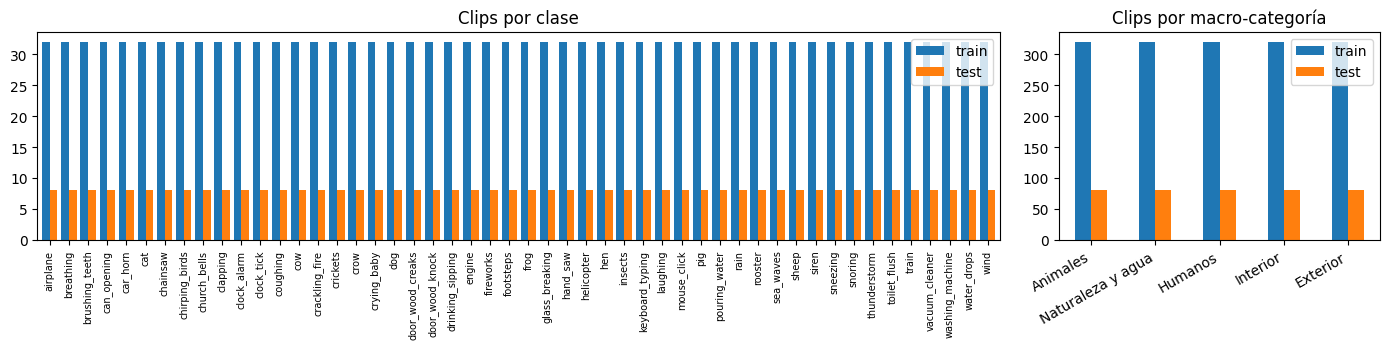

In [31]:
conteo = pd.DataFrame({'train': pd.Series(y_train).value_counts(),
                       'test': pd.Series(y_test).value_counts()}).sort_index().fillna(0).astype(int)
conteo.index = CLASES
print(f'Clips por clase -> train: {conteo["train"].min()}-{conteo["train"].max()} | test: {conteo["test"].min()}-{conteo["test"].max()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [3, 1]})
conteo.plot.bar(ax=axes[0], width=0.8, title='Clips por clase')
axes[0].tick_params(axis='x', labelsize=7)
macro_conteo = pd.DataFrame({'train': pd.Series(macro_de[y_train]).value_counts(),
                             'test': pd.Series(macro_de[y_test]).value_counts()}
                            ).reindex(range(len(MACROS)), fill_value=0)
macro_conteo.index = MACROS
macro_conteo.plot.bar(ax=axes[1], rot=30, title='Clips por macro-categoría')
plt.setp(axes[1].get_xticklabels(), ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exploracion_clases.png', dpi=300)
plt.show()

Forma de onda y espectrograma log-mel de un clip por macro-categoría. El espectrograma muestra cómo cambia la energía de cada banda de frecuencia en el tiempo: por ejemplo, la lluvia o el fuego se ven como ruido de banda ancha y continuo, mientras que un perro o una tos aparecen como eventos cortos y bien localizados. Varios clips de ESC-50 duran menos de 5 s y vienen completados con silencio digital (zona negra).

Se usa `n_fft = 1024` para que las 128 bandas mel tengan resolución suficiente en frecuencias bajas (con 400 puntos algunas bandas quedaban vacías).

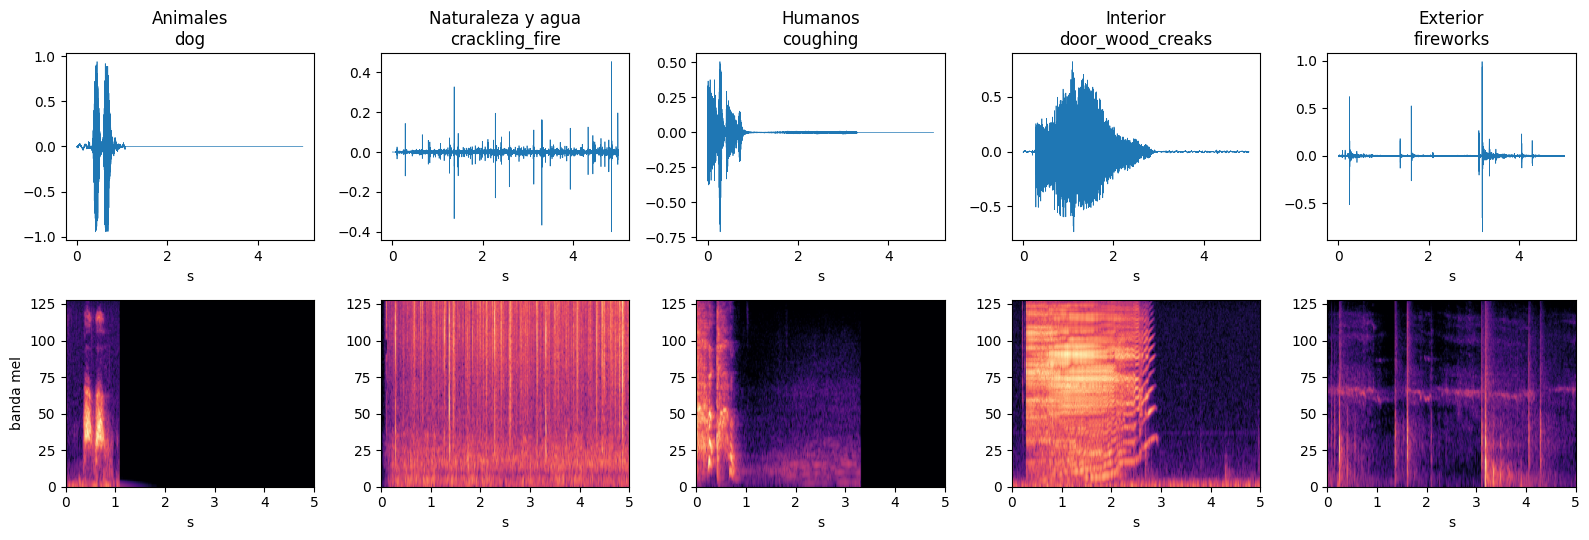

In [32]:
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=1024, win_length=400, hop_length=160, n_mels=128)
a_db = torchaudio.transforms.AmplitudeToDB(top_db=80)

fig, axes = plt.subplots(2, len(MACROS), figsize=(16, 5.5))
for k, m in enumerate(MACROS):
    i = np.where(macro_de[y_train] == k)[0][0]
    onda = ondas_train[i]
    t = np.arange(len(onda)) / SR
    axes[0, k].plot(t, onda, lw=0.5)
    axes[0, k].set(title=f'{m}\n{CLASES[y_train[i]]}', xlabel='s')
    espec = a_db(mel(torch.from_numpy(onda))).numpy()
    axes[1, k].imshow(espec, origin='lower', aspect='auto', cmap='magma',
                      extent=[0, len(onda) / SR, 0, 128])
    axes[1, k].set(xlabel='s', ylabel='banda mel' if k == 0 else '')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ejemplos_espectrogramas.png', dpi=300)
plt.show()

### 3. Procesamiento de audio: de onda a espectrograma para AST
Se usa el `ASTFeatureExtractor` del modelo, que reproduce exactamente el preprocesamiento con el que se preentrenó AST:

- Filterbank log-mel estilo Kaldi con 128 bandas, ventana de 25 ms (Hanning) y salto de 10 ms, es decir, 100 frames por segundo.
- Tamaño fijo: cada espectrograma se rellena con ceros o se trunca a `max_length = 1024` frames (10.24 s). Los clips de ESC-50 duran 5 s (unos 500 frames), así que la segunda mitad es relleno. Se mantienen los 1024 frames porque los embeddings de posición del modelo preentrenado están aprendidos para ese tamaño. Cambiarlo obligaría a interpolarlos.
- Normalización: se resta la media (-4.27) y se divide entre 2 veces la desviación estándar (4.57) de AudioSet, para que la entrada quede en la misma escala que vio el modelo en el preentrenamiento. Como el relleno se agrega antes de normalizar, en la entrada final vale (0 + 4.27) / 9.14 ≈ 0.47, igual que en el preentrenamiento de AST.

El resultado es una "imagen" de 1024 × 128 por clip, lista para entrar al modelo. Todos los espectrogramas se calculan una sola vez y se guardan en float16 para ahorrar memoria.

In [33]:
extractor = ASTFeatureExtractor.from_pretrained(MODELO)
print(f'sr: {extractor.sampling_rate} | bandas mel: {extractor.num_mel_bins} | max_length: {extractor.max_length} | '
      f'normalizar: {extractor.do_normalize} (media {extractor.mean}, std {extractor.std})')


def a_espectrogramas(ondas, lote=64):
    """Lista de ondas a 16 kHz -> tensor (N, 1024, 128) normalizado, en float16."""
    salida = []
    for i in range(0, len(ondas), lote):
        x = extractor(ondas[i:i + lote], sampling_rate=SR, return_tensors='pt')['input_values']
        salida.append(x.half())
    return torch.cat(salida)


X_train = a_espectrogramas(ondas_train)
X_test = a_espectrogramas(ondas_test)
ds_train = TensorDataset(X_train, torch.tensor(y_train, dtype=torch.long))
ds_test = TensorDataset(X_test, torch.tensor(y_test, dtype=torch.long))
loader_test = DataLoader(ds_test, batch_size=32)

print('Forma train:', tuple(X_train.shape), '| forma test:', tuple(X_test.shape))
frames_reales = int(info_train['duracion_s'].median() * 100)
reales = X_train[:, :frames_reales].float()
print(f'Parte con audio (primeros {frames_reales} frames): media {reales.mean():.3f}, std {reales.std():.3f}')
print(f'Valor del relleno: {X_train[0, -1, 0].item():.3f}')
del ondas_train   # ya no se necesitan; las ondas de test se guardan para escuchar errores

sr: 16000 | bandas mel: 128 | max_length: 1024 | normalizar: True (media -4.2677393, std 4.5689974)
Forma train: (1600, 1024, 128) | forma test: (400, 1024, 128)
Parte con audio (primeros 500 frames): media -0.279, std 0.588
Valor del relleno: 0.467


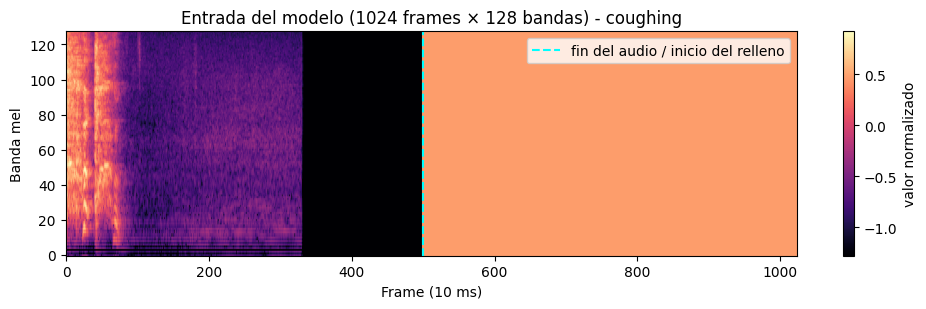

In [34]:
i = 0
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(X_train[i].float().T.numpy(), origin='lower', aspect='auto', cmap='magma')
ax.axvline(frames_reales, color='cyan', ls='--', label='fin del audio / inicio del relleno')
ax.set(title=f'Entrada del modelo (1024 frames × 128 bandas) - {CLASES[y_train[i]]}',
       xlabel='Frame (10 ms)', ylabel='Banda mel')
ax.legend(loc='upper right')
plt.colorbar(im, ax=ax, label='valor normalizado')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/entrada_modelo.png', dpi=300)
plt.show()

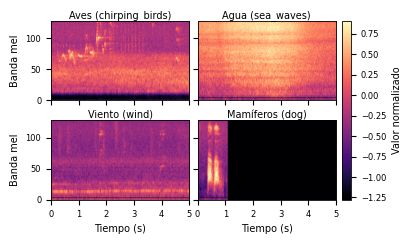

In [35]:
ejemplos = [('Aves', 'chirping_birds'), ('Agua', 'sea_waves'), ('Viento', 'wind'), ('Mamíferos', 'dog')]
vmin, vmax = np.percentile(X_train[:200, :frames_reales].float().numpy(), [1, 99.5])

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(2, 2, figsize=(ANCHO_COL, 2.3), sharex=True, sharey=True)
    for ax, (grupo, clase) in zip(axes.flat, ejemplos):
        i = np.where(y_train == idx_de[clase])[0][0]
        im = ax.imshow(X_train[i, :frames_reales].float().T.numpy(), origin='lower', aspect='auto',
                       cmap='magma', vmin=vmin, vmax=vmax, extent=[0, frames_reales / 100, 0, 128])
        ax.set_title(f'{grupo} ({clase})', pad=2)
    for ax in axes[1]:
        ax.set_xlabel('Tiempo (s)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Banda mel')
    fig.tight_layout(pad=0.3, h_pad=0.4, w_pad=0.4)
    cb = fig.colorbar(im, ax=axes, fraction=0.04, pad=0.02)
    cb.set_label('Valor normalizado')
    guardar_informe(fig, 'fig_entradas')
    plt.show()

### 4. Modelo
Se usa `ASTForAudioClassification` con los pesos `MIT/ast-finetuned-audioset-10-10-0.4593`:

- Por qué este modelo: es un AST preentrenado en ImageNet (pesos de DeiT) y luego ajustado en AudioSet (2 M de clips, 527 clases, mAP 0.459). AudioSet ya incluye muchos sonidos de ESC-50 (animales, lluvia, viento, motores), así que las representaciones aprendidas se transfieren muy bien y bastan 2 épocas de ajuste.
- Embedding de parches: el espectrograma de 1024 × 128 se divide en parches de 16 × 16 con solapamiento (paso 10), lo que da 12 × 101 = 1212 parches. Cada uno se proyecta linealmente a un vector de 768.
- Se agregan dos tokens especiales (`[CLS]` y de destilación) y embeddings de posición aprendidos.
- Codificador transformer de 12 capas (12 cabezas de auto-atención, 768 dimensiones): cada parche atiende a todos los demás, de modo que el modelo relaciona patrones lejanos en tiempo y frecuencia en una sola operación.
- Cabeza de clasificación: LayerNorm + densa 768 → 50 aplicada al promedio de los dos tokens especiales. La cabeza original de 527 clases se descarta (`ignore_mismatched_sizes=True`) y la nueva se inicializa al azar.
- Softmax: convierte los 50 logits en probabilidades. En entrenamiento va dentro de `CrossEntropyLoss`.

Se hace fine-tuning completo: se ajustan todos los pesos (unos 86 M), no solo la cabeza.

In [36]:
def crear_modelo():
    return ASTForAudioClassification.from_pretrained(
        MODELO, num_labels=len(CLASES), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True).to(device)


modelo = crear_modelo()
print(modelo.classifier)
N_PARAMS = sum(p.numel() for p in modelo.parameters())
print(f'Parámetros: {N_PARAMS:,}')
cfg = modelo.config
n_f = (cfg.num_mel_bins - cfg.patch_size) // cfg.frequency_stride + 1
n_t = (cfg.max_length - cfg.patch_size) // cfg.time_stride + 1
print(f'Espectrograma {cfg.max_length} x {cfg.num_mel_bins} -> {n_f} x {n_t} = {n_f * n_t} parches de {cfg.patch_size}x{cfg.patch_size}')
del modelo

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

ASTMLPHead(
  (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (dense): Linear(in_features=768, out_features=50, bias=True)
)
Parámetros: 86,227,250
Espectrograma 1024 x 128 -> 12 x 101 = 1212 parches de 16x16


### 5. Entrenamiento
- Optimizador AdamW con weight decay 0.01 y dos tasas de aprendizaje: 3e-5 para el cuerpo preentrenado, que es baja para no destruir lo aprendido en AudioSet, y 3e-4 (10 veces mayor) para la cabeza nueva, que parte de pesos aleatorios y debe converger en solo 2 épocas.
- Warmup lineal del 10 % de los pasos y luego decaimiento lineal a 0.
- Batch de 8, 2 épocas y pérdida de entropía cruzada.
- Gradient clipping a norma 1.0 y precisión mixta (fp16) en GPU.
- Para las curvas de aprendizaje se evalúa en prueba 4 veces por época y antes de entrenar. El dataset solo trae train y test, pero el test no se usa para elegir la época ni los hiperparámetros: el modelo que se reporta es siempre el del final de la época 2.

In [37]:
criterio = nn.CrossEntropyLoss()   # aplica log-softmax internamente


def grupos_parametros(modelo):
    """Separa la cabeza nueva (tasa LR_CABEZA) del cuerpo preentrenado (tasa LR)."""
    cabeza = [p for n, p in modelo.named_parameters() if n.startswith('classifier')]
    cuerpo = [p for n, p in modelo.named_parameters() if not n.startswith('classifier')]
    return [{'params': cuerpo, 'lr': LR}, {'params': cabeza, 'lr': LR_CABEZA}]


@torch.no_grad()
def evaluar(modelo, loader):
    """Devuelve (pérdida, exactitud) en el loader."""
    modelo.eval()
    perdida, aciertos = 0.0, 0
    for x, y in loader:
        x, y = x.to(device).float(), y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
            logits = modelo(input_values=x).logits
        perdida += criterio(logits.float(), y).item() * len(y)
        aciertos += (logits.argmax(1) == y).sum().item()
    return perdida / len(loader.dataset), aciertos / len(loader.dataset)


def entrenar(modelo, loader_train, epocas=EPOCAS):
    """Fine-tuning durante `epocas` épocas. Evalúa en prueba EVALS_POR_EPOCA veces por época para las curvas."""
    optimizador = torch.optim.AdamW(grupos_parametros(modelo), weight_decay=0.01)
    pasos_ep = len(loader_train)
    pasos = epocas * pasos_ep
    scheduler = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)
    scaler = torch.amp.GradScaler('cuda', enabled=USAR_AMP)
    eval_cada = max(1, pasos_ep // EVALS_POR_EPOCA)

    tl0, ta0 = evaluar(modelo, loader_test)   # punto de partida: cabeza aleatoria
    hist = {'epoca': [0.0], 'train_loss': [np.nan], 'train_acc': [np.nan], 'test_loss': [tl0], 'test_acc': [ta0]}
    paso, acum_loss, acum_ok, acum_n = 0, 0.0, 0, 0
    for ep in range(1, epocas + 1):
        modelo.train()
        for x, y in loader_train:
            x, y = x.to(device).float(), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
                logits = modelo(input_values=x).logits
                loss = criterio(logits.float(), y)
            optimizador.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizador)
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            scaler.step(optimizador)
            scaler.update()
            scheduler.step()

            paso += 1
            acum_loss += loss.item() * len(y)
            acum_ok += (logits.argmax(1) == y).sum().item()
            acum_n += len(y)
            if paso % eval_cada == 0 or paso == pasos:
                vl, va = evaluar(modelo, loader_test)
                for k, v in zip(hist, [paso / pasos_ep, acum_loss / acum_n, acum_ok / acum_n, vl, va]):
                    hist[k].append(v)
                acum_loss, acum_ok, acum_n = 0.0, 0, 0
                modelo.train()
        print(f'  época {ep:2d} | train loss {hist["train_loss"][-1]:.4f} acc {hist["train_acc"][-1]:.4f} | '
              f'test loss {hist["test_loss"][-1]:.4f} acc {hist["test_acc"][-1]:.4f}')
    return hist


@torch.no_grad()
def predecir(modelo, loader):
    """Devuelve (y_true, y_pred, probabilidades softmax por clase)."""
    modelo.eval()
    probs = []
    for x, _ in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
            logits = modelo(input_values=x.to(device).float()).logits
        probs.append(torch.softmax(logits.float(), dim=1).cpu())
    probs = torch.cat(probs).numpy()
    y_true = loader.dataset.tensors[1].numpy()
    return y_true, probs.argmax(1), probs


def metricas_globales(y_true, y_pred):
    return {'acc': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}

In [38]:
corridas = []   # una por semilla
for s in SEMILLAS:
    print(f'=== AST | semilla {s} ===')
    fijar_semilla(s)   # fija también la inicialización de la cabeza nueva y el orden de los lotes
    loader_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,
                              generator=torch.Generator().manual_seed(s))
    modelo = crear_modelo()
    t0 = time.time()
    hist = entrenar(modelo, loader_train)
    minutos = (time.time() - t0) / 60   # incluye las evaluaciones intermedias de las curvas

    y_true, y_pred, probs = predecir(modelo, loader_test)
    metricas = metricas_globales(y_true, y_pred)
    print('  -> test ' + ' | '.join(f'{k} {v:.4f}' for k, v in metricas.items()) + f' | {minutos:.1f} min\n')

    corridas.append({'semilla': s, 'hist': hist, **metricas, 'minutos': minutos,
                     'y_true': y_true, 'y_pred': y_pred, 'probs': probs})
    del modelo
    if device.type == 'cuda':
        torch.cuda.empty_cache()

=== AST | semilla 0 ===


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  época  1 | train loss 0.1993 acc 0.9500 | test loss 0.3418 acc 0.9200
  época  2 | train loss 0.0136 acc 1.0000 | test loss 0.2230 acc 0.9450
  -> test acc 0.9450 | precision 0.9530 | recall 0.9450 | f1 0.9408 | 4.5 min

=== AST | semilla 1 ===


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  época  1 | train loss 0.2423 acc 0.9350 | test loss 0.3154 acc 0.9000
  época  2 | train loss 0.0284 acc 0.9925 | test loss 0.1971 acc 0.9575
  -> test acc 0.9575 | precision 0.9594 | recall 0.9575 | f1 0.9558 | 4.7 min

=== AST | semilla 2 ===


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  época  1 | train loss 0.2584 acc 0.9375 | test loss 0.2928 acc 0.9050
  época  2 | train loss 0.0371 acc 0.9900 | test loss 0.1870 acc 0.9425
  -> test acc 0.9425 | precision 0.9471 | recall 0.9425 | f1 0.9410 | 4.8 min



### 5.1 Línea base: linear probe sobre el AST congelado
Para medir cuánto aporta el fine-tuning se entrena una línea base que no modifica el transformer: se extrae el embedding de cada clip (promedio de los tokens `[CLS]` y de destilación, 768 dimensiones) con el AST de AudioSet congelado, y sobre él se ajusta una regresión logística multi-clase (con estandarización previa).

Es equivalente a entrenar solo la cabeza lineal, con 38 450 parámetros entrenables frente a 86 M. Se usa la regularización por defecto (C = 1) para no ajustar hiperparámetros con el conjunto de prueba. Como es determinista, se corre una sola vez.

In [39]:
@torch.no_grad()
def extraer_embeddings(base, loader):
    """Embedding (promedio de [CLS] y destilación) de cada clip con el AST congelado."""
    base.eval()
    embs = []
    for x, _ in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
            embs.append(base(input_values=x.to(device).float()).pooler_output.float().cpu())
    return torch.cat(embs).numpy()


t0 = time.time()
base = ASTModel.from_pretrained(MODELO).to(device)
E_train = extraer_embeddings(base, DataLoader(ds_train, batch_size=32))
E_test = extraer_embeddings(base, loader_test)
del base
if device.type == 'cuda':
    torch.cuda.empty_cache()

lp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=1.0)).fit(E_train, y_train)
y_lp = lp.predict(E_test)
min_lp = (time.time() - t0) / 60
metricas_lp = metricas_globales(y_test, y_lp)
print('Embeddings:', E_train.shape, '| linear probe -> ' + ' | '.join(f'{k} {v:.4f}' for k, v in metricas_lp.items())
      + f' | {min_lp:.1f} min')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings: (1600, 768) | linear probe -> acc 0.9525 | precision 0.9550 | recall 0.9525 | f1 0.9515 | 0.7 min


### 6. Resultados cuantitativos
Métricas en prueba (%). Para el fine-tuning se reporta la media ± desviación estándar de las semillas. Precisión, recall y F1 son *macro*, es decir, el promedio simple de las 50 clases. La prueba de McNemar exacta compara los aciertos de ambos modelos clip a clip (fine-tuning con la primera semilla).

In [40]:
res = pd.DataFrame(corridas)
m, d = res[['acc', 'precision', 'recall', 'f1']].mean() * 100, res[['acc', 'precision', 'recall', 'f1']].std() * 100
tabla = pd.DataFrame({
    'Linear probe (AST congelado)': [f'{metricas_lp[k] * 100:.2f}' for k in ['acc', 'precision', 'recall', 'f1']]
                                    + [f'{(y_lp != y_test).sum()}', '0.04', f'{min_lp:.1f}'],
    'AST fine-tuning': [f'{m[k]:.2f} ± {d[k]:.2f}' for k in ['acc', 'precision', 'recall', 'f1']]
                       + [f'{np.mean([(c["y_pred"] != c["y_true"]).sum() for c in corridas]):.1f}',
                          f'{N_PARAMS / 1e6:.1f}', f'{res["minutos"].mean():.1f} ± {res["minutos"].std():.1f}']},
    index=['Exactitud (%)', 'Precisión macro (%)', 'Recall macro (%)', 'F1 macro (%)',
           f'Errores (de {len(y_test)})', 'Parámetros entrenables (M)', 'Tiempo (min)'])
tabla.to_csv(f'{FIG_DIR}/tabla_resultados.csv')

ok_ft, ok_lp = corridas[0]['y_pred'] == y_test, y_lp == y_test
b, c_ = int((ok_ft & ~ok_lp).sum()), int((~ok_ft & ok_lp).sum())
p_mc = binomtest(b, b + c_, 0.5).pvalue if b + c_ else 1.0
print(f'McNemar exacta: solo acierta el fine-tuning en {b} clips, solo el linear probe en {c_} -> p = {p_mc:.4f}')
print('Exactitud por semilla (%):', (res['acc'] * 100).round(2).tolist())
tabla

McNemar exacta: solo acierta el fine-tuning en 5 clips, solo el linear probe en 8 -> p = 0.5811
Exactitud por semilla (%): [94.5, 95.75, 94.25]


,Linear probe (AST congelado),AST fine-tuning
Exactitud (%),95.25,94.83 ± 0.80
Precisión macro (%),95.50,95.32 ± 0.61
Recall macro (%),95.25,94.83 ± 0.80
F1 macro (%),95.15,94.59 ± 0.86
Errores (de 400),19,20.7
Parámetros entrenables (M),0.04,86.2
Tiempo (min),0.7,4.7 ± 0.1


In [41]:
# Precisión, recall y F1 por clase (primera semilla)
print(classification_report(corridas[0]['y_true'], corridas[0]['y_pred'], labels=range(len(CLASES)),
                            target_names=CLASES, digits=4, zero_division=0))

                  precision    recall  f1-score   support

        airplane     1.0000    1.0000    1.0000         8
       breathing     1.0000    1.0000    1.0000         8
  brushing_teeth     1.0000    1.0000    1.0000         8
     can_opening     1.0000    1.0000    1.0000         8
        car_horn     1.0000    0.8750    0.9333         8
             cat     1.0000    1.0000    1.0000         8
        chainsaw     1.0000    0.8750    0.9333         8
  chirping_birds     1.0000    1.0000    1.0000         8
    church_bells     1.0000    1.0000    1.0000         8
        clapping     1.0000    1.0000    1.0000         8
     clock_alarm     0.8889    1.0000    0.9412         8
      clock_tick     1.0000    0.8750    0.9333         8
        coughing     1.0000    0.8750    0.9333         8
             cow     1.0000    1.0000    1.0000         8
  crackling_fire     1.0000    1.0000    1.0000         8
        crickets     0.8889    1.0000    0.9412         8
            c

#### 6.1 Curvas de aprendizaje
Pérdida y exactitud en prueba a lo largo del entrenamiento (media ± desviación estándar de las semillas). La pérdida de train es el promedio de los lotes de cada tramo, calculada en modo entrenamiento (con dropout y pesos que cambian), así que no es directamente comparable con la de prueba. La línea punteada es el linear probe.

/tmp/ipykernel_1241/942029893.py:7: RuntimeWarning: Mean of empty slice
  media, sd = np.nanmean(H[k], 0), np.nanstd(H[k], 0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


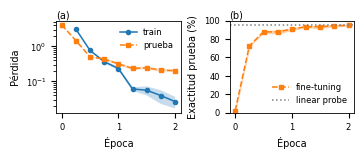

Exactitud de prueba en cada punto (media %): {np.float64(0.0): np.float64(2.3), np.float64(0.25): np.float64(72.6), np.float64(0.5): np.float64(87.9), np.float64(0.75): np.float64(87.6), np.float64(1.0): np.float64(90.8), np.float64(1.25): np.float64(93.4), np.float64(1.5): np.float64(93.2), np.float64(1.75): np.float64(94.5), np.float64(2.0): np.float64(94.8)}


In [42]:
H = {k: np.array([c['hist'][k] for c in corridas]) for k in ['train_loss', 'test_loss', 'test_acc']}
ep = np.array(corridas[0]['hist']['epoca'])

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COL, 1.45))
    for k, estilo, etq in [('train_loss', '-o', 'train'), ('test_loss', '--s', 'prueba')]:
        media, sd = np.nanmean(H[k], 0), np.nanstd(H[k], 0)
        axes[0].plot(ep, media, estilo, label=etq)
        axes[0].fill_between(ep, media - sd, media + sd, alpha=0.25)
    axes[0].set(xlabel='Época', ylabel='Pérdida', xticks=[0, 1, 2], yscale='log')
    axes[0].legend(frameon=False)
    media, sd = H['test_acc'].mean(0) * 100, H['test_acc'].std(0) * 100
    axes[1].plot(ep, media, '--s', color='C1', label='fine-tuning')
    axes[1].fill_between(ep, media - sd, media + sd, color='C1', alpha=0.25)
    axes[1].axhline(metricas_lp['acc'] * 100, color='gray', ls=':', label='linear probe')
    axes[1].set(xlabel='Época', ylabel='Exactitud prueba (%)', xticks=[0, 1, 2], ylim=(0, 100))
    axes[1].legend(frameon=False, loc='lower right')
    for ax, letra in zip(axes, 'ab'):
        ax.set_title(f'({letra})', loc='left', pad=2)
    fig.tight_layout(pad=0.3, w_pad=0.8)
    guardar_informe(fig, 'fig_curvas')
    plt.show()

print('Exactitud de prueba en cada punto (media %):', dict(zip(ep.round(2), (H['test_acc'].mean(0) * 100).round(1))))

#### 6.2 Análisis por clase
Precisión, recall y F1 de cada clase (media ± desviación estándar de las semillas) y F1 del linear probe. Se muestran las 10 clases con mejor y peor F1 para ver dónde rinde mejor y peor el modelo. Con 8 clips por clase en prueba, cada error equivale a 12.5 puntos de recall en esa clase.

Clases con F1 = 100 %: 20 de 50 (linear probe: 31)
Peores 10 por F1:
                              macro  precision  recall     f1  f1_lp
clase                                                              
washing_machine           Interior      80.83   45.83  54.68  70.59
wind             Naturaleza y agua      83.02   62.50  70.99  71.43
engine                    Exterior      70.56   87.50  77.59  82.35
footsteps                  Humanos     100.00   66.67  79.85  76.92
helicopter                Exterior      87.83   79.17  82.69  66.67
train                     Exterior      91.07   79.17  84.40  93.33
sea_waves        Naturaleza y agua      80.54  100.00  89.07  88.89
fireworks                 Exterior      91.67   87.50  89.44  87.50
vacuum_cleaner            Interior      85.46   95.83  90.17  94.12
coughing                   Humanos     100.00   87.50  93.33  93.33


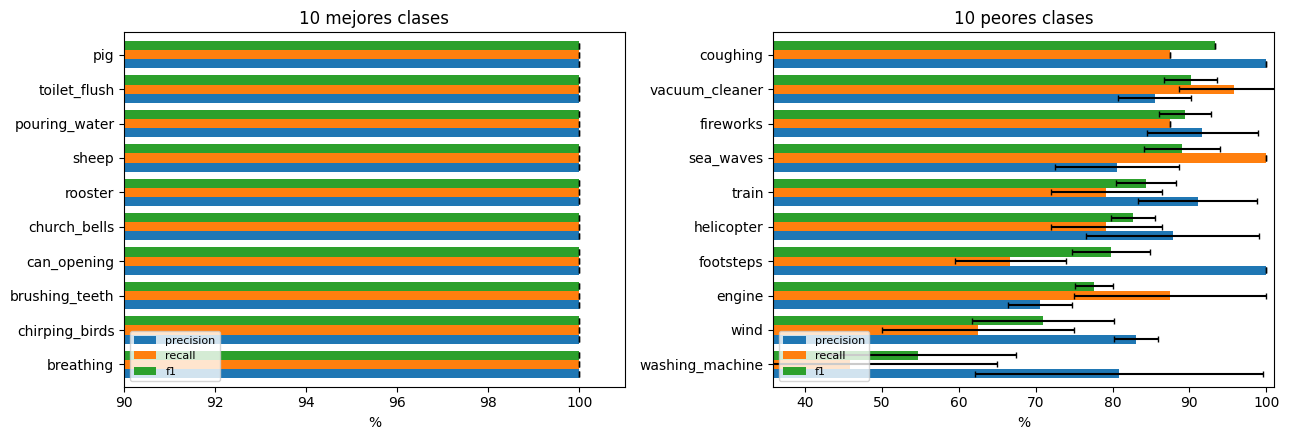

In [43]:
filas = []
for c in corridas:
    p, r, f, _ = precision_recall_fscore_support(c['y_true'], c['y_pred'], labels=range(len(CLASES)), zero_division=0)
    filas.append(pd.DataFrame({'clase': CLASES, 'precision': p, 'recall': r, 'f1': f}))
por_clase = pd.concat(filas).groupby('clase', sort=False)[['precision', 'recall', 'f1']]
medias, desv = por_clase.mean().mul(100), por_clase.std().fillna(0).mul(100)
medias['macro'] = [MACROS[macro_de[label2id[c]]] for c in medias.index]
medias['f1_lp'] = f1_score(y_test, y_lp, labels=range(len(CLASES)), average=None, zero_division=0) * 100

resumen = (medias[['precision', 'recall', 'f1']].round(2).astype(str) + ' ± '
           + desv[['precision', 'recall', 'f1']].round(2).astype(str))
resumen.insert(0, 'macro', medias['macro'])
resumen['f1 linear probe'] = medias['f1_lp'].round(2)
resumen.sort_values('f1').to_csv(f'{FIG_DIR}/metricas_por_clase.csv')

orden = medias.sort_values('f1')
peores, mejores = orden.head(10), orden.tail(10)
print(f'Clases con F1 = 100 %: {(medias["f1"] >= 99.99).sum()} de {len(CLASES)} '
      f'(linear probe: {(medias["f1_lp"] >= 99.99).sum()})')
print('Peores 10 por F1:\n', peores[['macro', 'precision', 'recall', 'f1', 'f1_lp']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, sub, titulo in zip(axes, [mejores, peores], ['10 mejores clases', '10 peores clases']):
    sub[['precision', 'recall', 'f1']].plot.barh(ax=ax, xerr=desv.loc[sub.index, ['precision', 'recall', 'f1']],
                                                  capsize=2, width=0.8)
    ax.set(xlim=(max(0, sub[['precision', 'recall', 'f1']].values.min() - 10), 101), xlabel='%', ylabel='', title=titulo)
    ax.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/metricas_por_clase.png', dpi=300)
plt.show()

#### 6.3 Matriz de confusión
Suma de las semillas, normalizada por fila (%): la fila es la clase real y la columna la predicción. La diagonal es el recall de cada clase. Las clases se ordenan por macro-categoría para que los bloques de la diagonal muestren las confusiones dentro de la misma familia de sonidos. Esta matriz completa es para el notebook; para el informe se genera abajo una versión reducida, legible a ancho de columna.

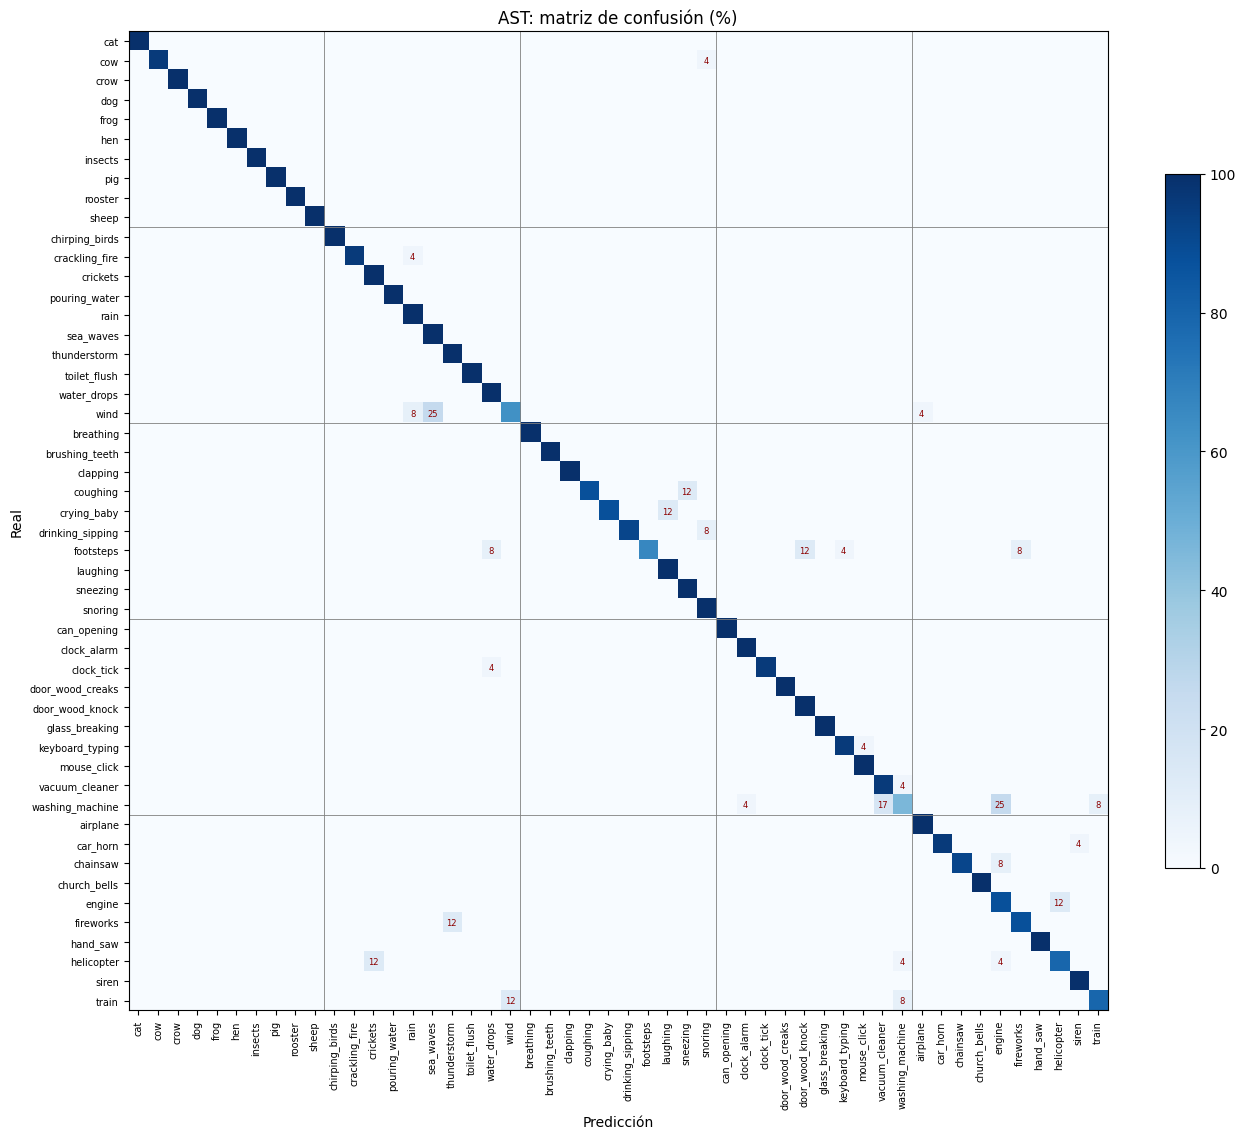

In [44]:
n = len(CLASES)
cm_cnt = sum(confusion_matrix(c['y_true'], c['y_pred'], labels=range(n)) for c in corridas)
cm = cm_cnt / cm_cnt.sum(axis=1, keepdims=True).clip(min=1) * 100

orden_idx = np.argsort(macro_de, kind='stable')
cm_ord = cm[np.ix_(orden_idx, orden_idx)]
fig, ax = plt.subplots(figsize=(13, 11.5))
im = ax.imshow(cm_ord, cmap='Blues', vmin=0, vmax=100)
etq = [CLASES[i] for i in orden_idx]
ax.set(xticks=range(n), yticks=range(n), title='AST: matriz de confusión (%)', xlabel='Predicción', ylabel='Real')
ax.set_xticklabels(etq, rotation=90, fontsize=7)
ax.set_yticklabels(etq, fontsize=7)
limites = np.cumsum(np.bincount(macro_de))[:-1] - 0.5
for b_ in limites:
    ax.axhline(b_, color='gray', lw=0.6)
    ax.axvline(b_, color='gray', lw=0.6)
for i in range(n):
    for j in range(n):
        if i != j and cm_ord[i, j] > 0:
            ax.text(j, i, f'{cm_ord[i, j]:.0f}', ha='center', va='center', fontsize=6, color='darkred')
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/matriz_confusion.png', dpi=300)
plt.show()

Pares de clases más confundidos (fuera de la diagonal), con el porcentaje de clips de la clase real que se asignaron a la clase predicha.

In [45]:
pares = [(CLASES[i], CLASES[j], cm_cnt[i, j], cm[i, j], macro_de[i] == macro_de[j])
         for i in range(n) for j in range(n) if i != j and cm_cnt[i, j] > 0]
pares_df = (pd.DataFrame(pares, columns=['real', 'prediccion', 'clips', '% de la clase', 'misma macro'])
            .sort_values(['clips', '% de la clase'], ascending=False).reset_index(drop=True))
confusos = pares_df.head(15).round(1)
confusos.to_csv(f'{FIG_DIR}/pares_mas_confundidos.csv', index=False)
n_err = cm_cnt.sum() - np.trace(cm_cnt)
n_misma = pares_df.loc[pares_df['misma macro'], 'clips'].sum()
print(f'Errores totales (todas las semillas): {n_err} | dentro de la misma macro-categoría: {n_misma} ({n_misma / max(n_err, 1):.0%})')
confusos

Errores totales (todas las semillas): 62 | dentro de la misma macro-categoría: 31 (50%)


,real,prediccion,clips,% de la clase,misma macro
0,washing_machine,engine,6,25.0,False
1,wind,sea_waves,6,25.0,True
2,washing_machine,vacuum_cleaner,4,16.7,True
3,coughing,sneezing,3,12.5,True
4,crying_baby,laughing,3,12.5,True
5,engine,helicopter,3,12.5,True
6,fireworks,thunderstorm,3,12.5,False
7,footsteps,door_wood_knock,3,12.5,False
8,helicopter,crickets,3,12.5,False
9,train,wind,3,12.5,False


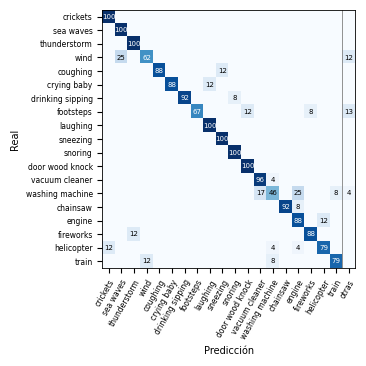

In [46]:
top = pares_df[pares_df['clips'] >= 2].head(12)
if len(top) < 4:   # si casi no hay confusiones repetidas, se toman los primeros pares
    top = pares_df.head(8)
sel = list(dict.fromkeys([label2id[c] for c in pd.concat([top['real'], top['prediccion']])]))
sel = sorted(sel, key=lambda i: (macro_de[i], CLASES[i]))
sub = cm[np.ix_(sel, sel)]
sub = np.column_stack([sub, 100 - sub.sum(axis=1)])   # columna "otras"
etq_f = [CLASES[i].replace('_', ' ') for i in sel]

with plt.rc_context(ESTILO_INFORME):
    lado = 0.19 * len(sel) + 1.0
    fig, ax = plt.subplots(figsize=(ANCHO_COL, min(lado, ANCHO_COL)))
    ax.imshow(sub, cmap='Blues', vmin=0, vmax=100, aspect='auto')
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            if sub[i, j] >= 0.5:
                ax.text(j, i, f'{sub[i, j]:.0f}', ha='center', va='center', fontsize=5,
                        color='white' if sub[i, j] > 55 else 'black')
    ax.set_xticks(range(sub.shape[1]))
    ax.set_xticklabels(etq_f + ['otras'], rotation=60, ha='right', rotation_mode='anchor', fontsize=5.5)
    ax.set_yticks(range(len(sel)))
    ax.set_yticklabels(etq_f, fontsize=5.5)
    ax.axvline(len(sel) - 0.5, color='gray', lw=0.6)
    ax.set(xlabel='Predicción', ylabel='Real')
    fig.tight_layout(pad=0.2)
    guardar_informe(fig, 'fig_confusion')
    plt.show()

#### 6.4 Análisis por macro-categoría y por las categorías del enunciado
Las predicciones de 50 clases se agrupan en las 5 macro-categorías de ESC-50. Un error dentro de la misma macro-categoría (por ejemplo, viento → olas) es menos grave que uno entre familias distintas (por ejemplo, lavadora → motor).

Exactitud a nivel macro-categoría: 97.42 %


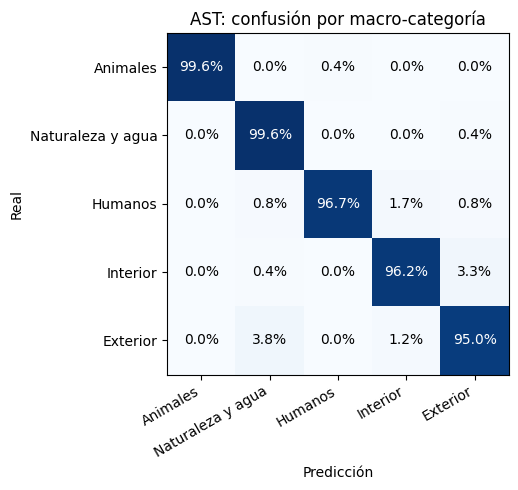

,precision,recall,f1,f1 medio de sus clases,f1 medio clases (linear probe)
macro,,,,,
Animales,100.00,99.58,99.79,99.78,100.00
Naturaleza y agua,95.23,99.58,97.35,93.47,94.86
Humanos,99.57,96.67,98.10,94.46,95.18
Interior,97.08,96.25,96.65,92.86,93.38
Exterior,95.40,95.00,95.20,92.35,92.32


In [47]:
filas_m = []
for c in corridas:
    yt, yp = macro_de[c['y_true']], macro_de[c['y_pred']]
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=range(len(MACROS)), zero_division=0)
    filas_m.append(pd.DataFrame({'macro': MACROS, 'acc_macro': accuracy_score(yt, yp),
                                 'precision': p, 'recall': r, 'f1': f}))
tabla_macro = pd.concat(filas_m).groupby('macro', sort=False)[['precision', 'recall', 'f1']].mean().mul(100)
tabla_macro['f1 medio de sus clases'] = medias.groupby('macro')['f1'].mean().reindex(MACROS)
tabla_macro['f1 medio clases (linear probe)'] = medias.groupby('macro')['f1_lp'].mean().reindex(MACROS)
tabla_macro = tabla_macro.round(2)
tabla_macro.to_csv(f'{FIG_DIR}/metricas_por_macro.csv')
print(f'Exactitud a nivel macro-categoría: {pd.concat(filas_m)["acc_macro"].mean() * 100:.2f} %')

cm_m = sum(confusion_matrix(macro_de[c['y_true']], macro_de[c['y_pred']], labels=range(len(MACROS))) for c in corridas)
cm_m = cm_m / cm_m.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm_m, cmap='Blues', vmin=0, vmax=100)
for i in range(len(MACROS)):
    for j in range(len(MACROS)):
        ax.text(j, i, f'{cm_m[i, j]:.1f}%', ha='center', va='center', color='white' if cm_m[i, j] > 50 else 'black')
ax.set(xticks=range(len(MACROS)), yticks=range(len(MACROS)), xticklabels=MACROS, yticklabels=MACROS,
       title='AST: confusión por macro-categoría', xlabel='Predicción', ylabel='Real')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/matriz_confusion_macro.png', dpi=300)
plt.show()
tabla_macro

Categorías del enunciado: F1 y recall medios de sus clases (fine-tuning y linear probe) y la confusión más frecuente de cada grupo.

In [48]:
filas_g = []
for g, clases_g in GRUPOS_ENUNCIADO.items():
    ids = [idx_de[c] for c in clases_g if c in idx_de]
    nombres_g = [CLASES[i] for i in ids]
    fuera = cm_cnt[ids].copy()
    fuera[np.arange(len(ids)), ids] = 0   # quita los aciertos
    i_max, j_max = np.unravel_index(fuera.argmax(), fuera.shape)
    filas_g.append({'grupo': g, 'clases': ', '.join(nombres_g),
                    'F1 fine-tuning': medias.loc[nombres_g, 'f1'].mean(),
                    'Recall fine-tuning': medias.loc[nombres_g, 'recall'].mean(),
                    'F1 linear probe': medias.loc[nombres_g, 'f1_lp'].mean(),
                    'errores (3 semillas)': int(fuera.sum()),
                    'confusión principal': (f'{CLASES[ids[i_max]]} → {CLASES[j_max]} ({fuera.max()})'
                                            if fuera.max() > 0 else '-')})
tabla_grupos = pd.DataFrame(filas_g).set_index('grupo').round(2)
tabla_grupos.to_csv(f'{FIG_DIR}/metricas_categorias_enunciado.csv')
tabla_grupos

,clases,F1 fine-tuning,Recall fine-tuning,F1 linear probe,errores (3 semillas),confusión principal
grupo,,,,,,
Aves,"chirping_birds, crow, hen, rooster",100.00,100.00,100.00,0,-
Agua,"rain, sea_waves, water_drops, pouring_water, t...",95.55,100.00,96.60,0,-
Viento,wind,70.99,62.50,71.43,9,wind → sea_waves (6)
Mamíferos,"dog, cat, cow, pig, sheep",99.56,99.17,100.00,1,cow → snoring (1)


### 7. Resultados cualitativos
#### 7.1 Errores más confiados (primera semilla)
Clips de prueba mal clasificados en los que el modelo estaba más seguro. Se pueden escuchar para entender si el error es razonable (por ejemplo, un clip de viento que suena muy parecido a olas). R = real, P = predicción.

In [49]:
c = corridas[0]
confianza = c['probs'].max(axis=1)


def mostrar(i, escuchar=True):
    """Imprime la clase real, la predicción y las 3 clases más probables de un clip de prueba."""
    top3 = np.argsort(-c['probs'][i])[:3]
    print(f'{nombres_test[i]} | R: {CLASES[c["y_true"][i]]} | P: {CLASES[c["y_pred"][i]]} (p = {confianza[i]:.2f}) | '
          'top-3: ' + ', '.join(f'{CLASES[k]} {c["probs"][i, k]:.2f}' for k in top3))
    if escuchar:
        display(AudioPlayer(ondas_test[i], rate=SR))


errores = np.where(c['y_true'] != c['y_pred'])[0]
errores = errores[np.argsort(-confianza[errores])]
print(f'Errores en prueba: {len(errores)} de {len(c["y_true"])}\n')
for i in errores[:5]:
    mostrar(i)

Errores en prueba: 22 de 400

clip_222 | R: washing_machine | P: engine (p = 0.99) | top-3: engine 0.99, door_wood_creaks 0.00, washing_machine 0.00


clip_272 | R: washing_machine | P: train (p = 0.99) | top-3: train 0.99, washing_machine 0.00, hand_saw 0.00


clip_165 | R: washing_machine | P: engine (p = 0.99) | top-3: engine 0.99, door_wood_creaks 0.00, washing_machine 0.00


clip_263 | R: washing_machine | P: vacuum_cleaner (p = 0.99) | top-3: vacuum_cleaner 0.99, washing_machine 0.01, siren 0.00


clip_152 | R: footsteps | P: door_wood_knock (p = 0.98) | top-3: door_wood_knock 0.98, footsteps 0.01, drinking_sipping 0.00


In [50]:
print('--- Aciertos más confiados (uno por macro-categoría) ---')
aciertos = np.where(c['y_true'] == c['y_pred'])[0]
for k in range(len(MACROS)):
    idx = aciertos[macro_de[c['y_true'][aciertos]] == k]
    if len(idx):
        print(f'[{MACROS[k]}]', end=' ')
        mostrar(idx[np.argmax(confianza[idx])])

--- Aciertos más confiados (uno por macro-categoría) ---
[Animales] clip_232 | R: dog | P: dog (p = 1.00) | top-3: dog 1.00, cat 0.00, can_opening 0.00


[Naturaleza y agua] clip_265 | R: rain | P: rain (p = 1.00) | top-3: rain 1.00, crackling_fire 0.00, wind 0.00


[Humanos] clip_134 | R: clapping | P: clapping (p = 1.00) | top-3: clapping 1.00, fireworks 0.00, glass_breaking 0.00


[Interior] clip_91 | R: door_wood_creaks | P: door_wood_creaks (p = 1.00) | top-3: door_wood_creaks 1.00, water_drops 0.00, snoring 0.00


[Exterior] clip_11 | R: fireworks | P: fireworks (p = 1.00) | top-3: fireworks 1.00, clapping 0.00, footsteps 0.00


#### 7.2 Espectrogramas de los errores

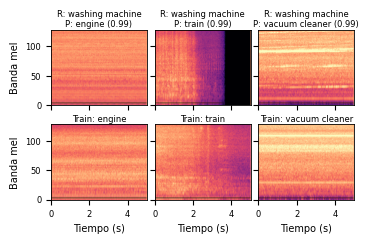

In [51]:
vistos, elegidos = set(), []
for i in errores:
    par = (c['y_true'][i], c['y_pred'][i])
    if par not in vistos:
        vistos.add(par)
        elegidos.append(i)
    if len(elegidos) == 3:
        break

if elegidos:
    with plt.rc_context(ESTILO_INFORME):
        fig, axes = plt.subplots(2, len(elegidos), figsize=(ANCHO_COL, 2.3), sharex=True, sharey=True, squeeze=False)
        for k, i in enumerate(elegidos):
            real, pred = c['y_true'][i], c['y_pred'][i]
            xt = X_test[i, :frames_reales].float()
            cand = np.where(y_train == pred)[0]
            dist = ((X_train[cand, :frames_reales].float() - xt) ** 2).mean(dim=(1, 2))
            j = cand[int(dist.argmin())]
            for fila, (x, titulo) in enumerate([
                    (xt, f'R: {CLASES[real]}\nP: {CLASES[pred]} ({confianza[i]:.2f})'),
                    (X_train[j, :frames_reales].float(), f'Train: {CLASES[pred]}')]):
                im = axes[fila, k].imshow(x.T.numpy(), origin='lower', aspect='auto', cmap='magma',
                                          vmin=vmin, vmax=vmax, extent=[0, frames_reales / 100, 0, 128])
                axes[fila, k].set_title(titulo.replace('_', ' '), pad=2, fontsize=6)
            axes[1, k].set_xlabel('Tiempo (s)')
        for fila in range(2):
            axes[fila, 0].set_ylabel('Banda mel')
        fig.tight_layout(pad=0.3, h_pad=0.4, w_pad=0.3)
        guardar_informe(fig, 'fig_errores')
        plt.show()

### 8. Exportar resultados
Se comprimen las figuras y las tablas en `resultados_informe.zip` para descargarlas desde Colab. Las figuras `informe_fig_*.png` están listas para insertarse a ancho de una columna.

In [52]:
print(sorted(os.listdir(FIG_DIR)))
shutil.make_archive('resultados_informe', 'zip', FIG_DIR)
try:
    from google.colab import files
    files.download('resultados_informe.zip')
except ImportError:
    print('Archivo listo:', os.path.abspath('resultados_informe.zip'))

['curvas_aprendizaje.png', 'ejemplos_espectrogramas.png', 'entrada_modelo.png', 'espectrogramas_errores.png', 'exploracion_clases.png', 'informe_fig_confusion.png', 'informe_fig_curvas.png', 'informe_fig_entradas.png', 'informe_fig_errores.png', 'matriz_confusion.png', 'matriz_confusion_macro.png', 'metricas_categorias_enunciado.csv', 'metricas_por_clase.csv', 'metricas_por_clase.png', 'metricas_por_macro.csv', 'pares_mas_confundidos.csv', 'tabla_resultados.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>